# Training Neural Networks Well — an in-depth PyTorch notebook

**Topics**
1. Training vs validation loss and metrics
2. Underfitting and overfitting
3. Learning rate and optimizer choices
4. SGD and Adam / AdamW
5. Regularization: weight decay and dropout
6. Early stopping and checkpointing
7. Batch normalization
8. Class imbalance and data augmentation
9. Learning-rate scheduling
10. Experiment tracking and reproducibility

**How it works:** Section 0 builds a small, reusable **training toolkit** (data loaders, model builder, `fit()` with history,
plots). Every later section uses it, so you can focus on *one idea at a time* and compare runs fairly — same data, same seed,
only one thing changed.

Each section: **concept → code → real output → 🔍 what to notice → ✍️ exercise**. Everything runs on a CPU in a few minutes.

## 0. Setup and training toolkit

In [1]:
import os, sys, json, time, random, copy, platform
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, Dataset, WeightedRandomSampler
from sklearn.datasets import make_moons, make_classification, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, balanced_accuracy_score, classification_report)

SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams["figure.figsize"] = (7, 3.6)
pd.set_option("display.width", 120)

print("Python ", platform.python_version())
print("PyTorch", torch.__version__, "| device:", device)

Python  3.13.18
PyTorch 2.15.0+cu132 | device: cpu


In [2]:
def set_seed(seed=SEED):
    # Seed every random generator we use
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def to_loaders(X_tr, y_tr, X_va, y_va, batch_size=32, seed=SEED, sampler=None):
    tr = TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.long))
    va = TensorDataset(torch.tensor(X_va, dtype=torch.float32), torch.tensor(y_va, dtype=torch.long))
    g = torch.Generator().manual_seed(seed)              # reproducible shuffling
    train_dl = DataLoader(tr, batch_size=batch_size, shuffle=sampler is None, sampler=sampler, generator=g)
    val_dl = DataLoader(va, batch_size=256)
    return train_dl, val_dl

def moons_loaders(n=1000, noise=0.3, n_train=None, batch_size=32, seed=SEED):
    X, y = make_moons(n, noise=noise, random_state=seed)
    X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
    if n_train:                                          # optionally keep only a few training points
        X_tr, y_tr = X_tr[:n_train], y_tr[:n_train]
    sc = StandardScaler().fit(X_tr)                      # fit scaling on TRAIN only
    return to_loaders(sc.transform(X_tr), y_tr, sc.transform(X_va), y_va, batch_size, seed)

def make_mlp(n_in=2, hidden=64, depth=2, n_out=2, dropout=0.0, batchnorm=False):
    layers, d = [], n_in
    for _ in range(depth):
        layers.append(nn.Linear(d, hidden))
        if batchnorm: layers.append(nn.BatchNorm1d(hidden))
        layers.append(nn.ReLU())
        if dropout: layers.append(nn.Dropout(dropout))
        d = hidden
    layers.append(nn.Linear(d, n_out))
    return nn.Sequential(*layers)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

In [3]:
def make_optimizer(name, params, lr, wd=0.0, momentum=0.0):
    name = name.lower()
    if name == "sgd":   return torch.optim.SGD(params, lr=lr, momentum=momentum, weight_decay=wd)
    if name == "adam":  return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if name == "adamw": return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(name)

def make_scheduler(name, opt, epochs, steps_per_epoch):
    # returns (scheduler, when_to_step)
    if name is None:       return None, None
    if name == "step":     return torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs // 3), gamma=0.3), "epoch"
    if name == "cosine":   return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs), "epoch"
    if name == "onecycle": return torch.optim.lr_scheduler.OneCycleLR(
                                   opt, max_lr=opt.param_groups[0]["lr"], epochs=epochs,
                                   steps_per_epoch=steps_per_epoch), "batch"
    if name == "plateau":  return torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.3, patience=5), "plateau"
    raise ValueError(name)

def run_epoch(model, loader, loss_fn, opt=None, sched=None, sched_mode=None):
    training = opt is not None
    model.train(training)                       # train mode: dropout/BN active; eval mode: off/frozen
    total, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)
            if training:
                opt.zero_grad(); loss.backward(); opt.step()
                if sched_mode == "batch": sched.step()
            total += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n

In [4]:
class EarlyStopping:
    # Stop when val loss hasn't improved by min_delta for `patience` epochs; keep the best weights.
    def __init__(self, patience=10, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.best_epoch, self.bad_epochs, self.best_state = float("inf"), 0, 0, None
    def step(self, val_loss, model, epoch):
        if val_loss < self.best - self.min_delta:
            self.best, self.best_epoch, self.bad_epochs = val_loss, epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
            return False
        self.bad_epochs += 1
        return self.bad_epochs >= self.patience          # True → stop

def fit(model, train_dl, val_dl, epochs=50, opt="adam", lr=1e-3, wd=0.0, momentum=0.0,
        sched=None, early_stopping=None, ckpt_path=None, loss_fn=None, seed=SEED, verbose=0):
    set_seed(seed)
    model = model.to(device)
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    optimizer = make_optimizer(opt, model.parameters(), lr, wd, momentum)
    scheduler, mode = make_scheduler(sched, optimizer, epochs, len(train_dl))
    rows = []
    for epoch in range(1, epochs + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(model, train_dl, loss_fn, optimizer, scheduler, mode)
        va_loss, va_acc = run_epoch(model, val_dl, loss_fn)
        rows.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc, lr=lr_now))
        if mode == "epoch":   scheduler.step()
        if mode == "plateau": scheduler.step(va_loss)
        if verbose and (epoch == 1 or epoch % verbose == 0):
            print(f"epoch {epoch:3d} | train {tr_loss:.3f} / {tr_acc:.3f} | val {va_loss:.3f} / {va_acc:.3f} | lr {lr_now:.5f}")
        if early_stopping is not None:
            improved_before = early_stopping.best
            stop = early_stopping.step(va_loss, model, epoch)
            if ckpt_path and early_stopping.best < improved_before:      # new best → checkpoint to disk
                torch.save({"epoch": epoch, "model_state": model.state_dict(),
                            "optimizer_state": optimizer.state_dict(), "val_loss": va_loss}, ckpt_path)
            if stop:
                if verbose: print(f"Early stop at epoch {epoch}; best epoch {early_stopping.best_epoch}")
                break
    if early_stopping is not None and early_stopping.best_state is not None:
        model.load_state_dict(early_stopping.best_state)               # restore best weights
    return pd.DataFrame(rows).set_index("epoch")

def plot_runs(runs, metrics=("train_loss", "val_loss"), title="", ylim=None, logy=False):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.2 * len(metrics), 3.4))
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, metrics):
        for name, h in runs.items():
            ax.plot(h.index, h[m], label=name)
        ax.set_title(m); ax.set_xlabel("epoch")
        if ylim: ax.set_ylim(*ylim)
        if logy: ax.set_yscale("log")
    axes[-1].legend(fontsize=8)
    if title: fig.suptitle(title)
    plt.tight_layout(); plt.show()

def summary(runs):
    out = {}
    for name, h in runs.items():
        best = h.val_loss.idxmin()
        out[name] = dict(final_train_loss=h.train_loss.iloc[-1], final_val_loss=h.val_loss.iloc[-1],
                         best_val_loss=h.val_loss.min(), best_epoch=best,
                         final_val_acc=h.val_acc.iloc[-1], gap=h.val_loss.iloc[-1] - h.train_loss.iloc[-1])
    return pd.DataFrame(out).T.round(3)

**The data.** Most sections use **two moons**: a 2-D, two-class problem with a curved boundary — easy to visualise, hard
enough that model size matters. We keep 70% for training and 30% for validation.

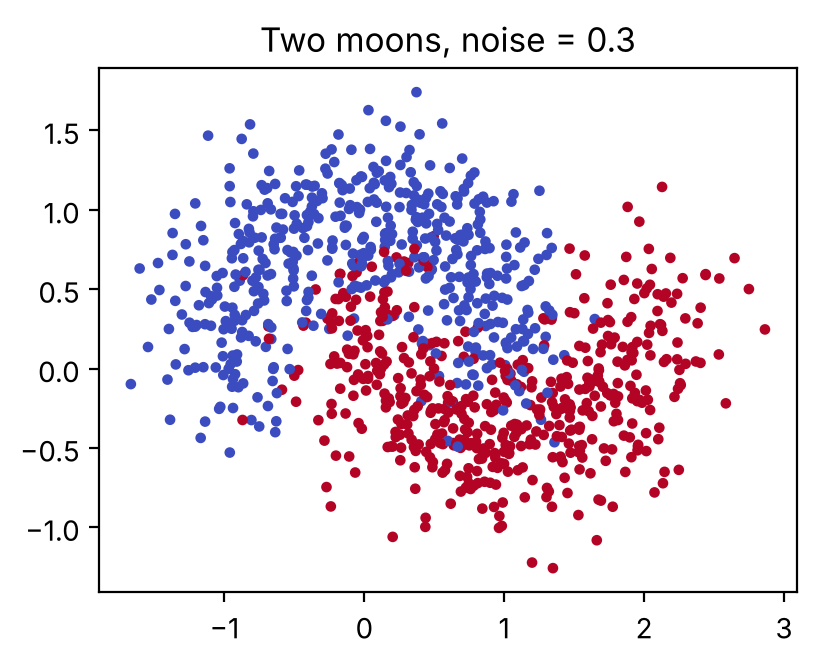

train batches: 22 | val batches: 2 | train size: 700 | val size: 300


In [5]:
X, y = make_moons(1000, noise=0.3, random_state=SEED)
plt.figure(figsize=(4.5, 3.4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=8)
plt.title("Two moons, noise = 0.3"); plt.show()
train_dl, val_dl = moons_loaders()
print("train batches:", len(train_dl), "| val batches:", len(val_dl),
      "| train size:", len(train_dl.dataset), "| val size:", len(val_dl.dataset))

---
## 1. Training vs validation loss and metrics

* **Training loss** — measured on data the model *learns from*. It almost always goes down.
* **Validation loss** — measured on held-out data the model never trains on. It tells you whether learning **generalises**.
* **Metrics** (accuracy, precision, recall, F1) are what humans care about; the **loss** is what the optimizer can differentiate.
  They usually move together, but not always: loss also measures *confidence*.

| | Loss (cross-entropy) | Accuracy |
|---|---|---|
| Smooth / differentiable | ✅ used for training | ❌ |
| Sensitive to confidence | ✅ a confident mistake costs a lot | ❌ right is right |
| Easy to explain | ❌ | ✅ |

parameters: 1218


epoch   1 | train 0.639 / 0.770 | val 0.571 / 0.857 | lr 0.00100


epoch  10 | train 0.297 / 0.859 | val 0.240 / 0.903 | lr 0.00100
epoch  20 | train 0.225 / 0.911 | val 0.192 / 0.937 | lr 0.00100


epoch  30 | train 0.206 / 0.907 | val 0.187 / 0.913 | lr 0.00100


epoch  40 | train 0.203 / 0.911 | val 0.186 / 0.923 | lr 0.00100


epoch  50 | train 0.201 / 0.909 | val 0.190 / 0.910 | lr 0.00100


epoch  60 | train 0.199 / 0.909 | val 0.190 / 0.913 | lr 0.00100


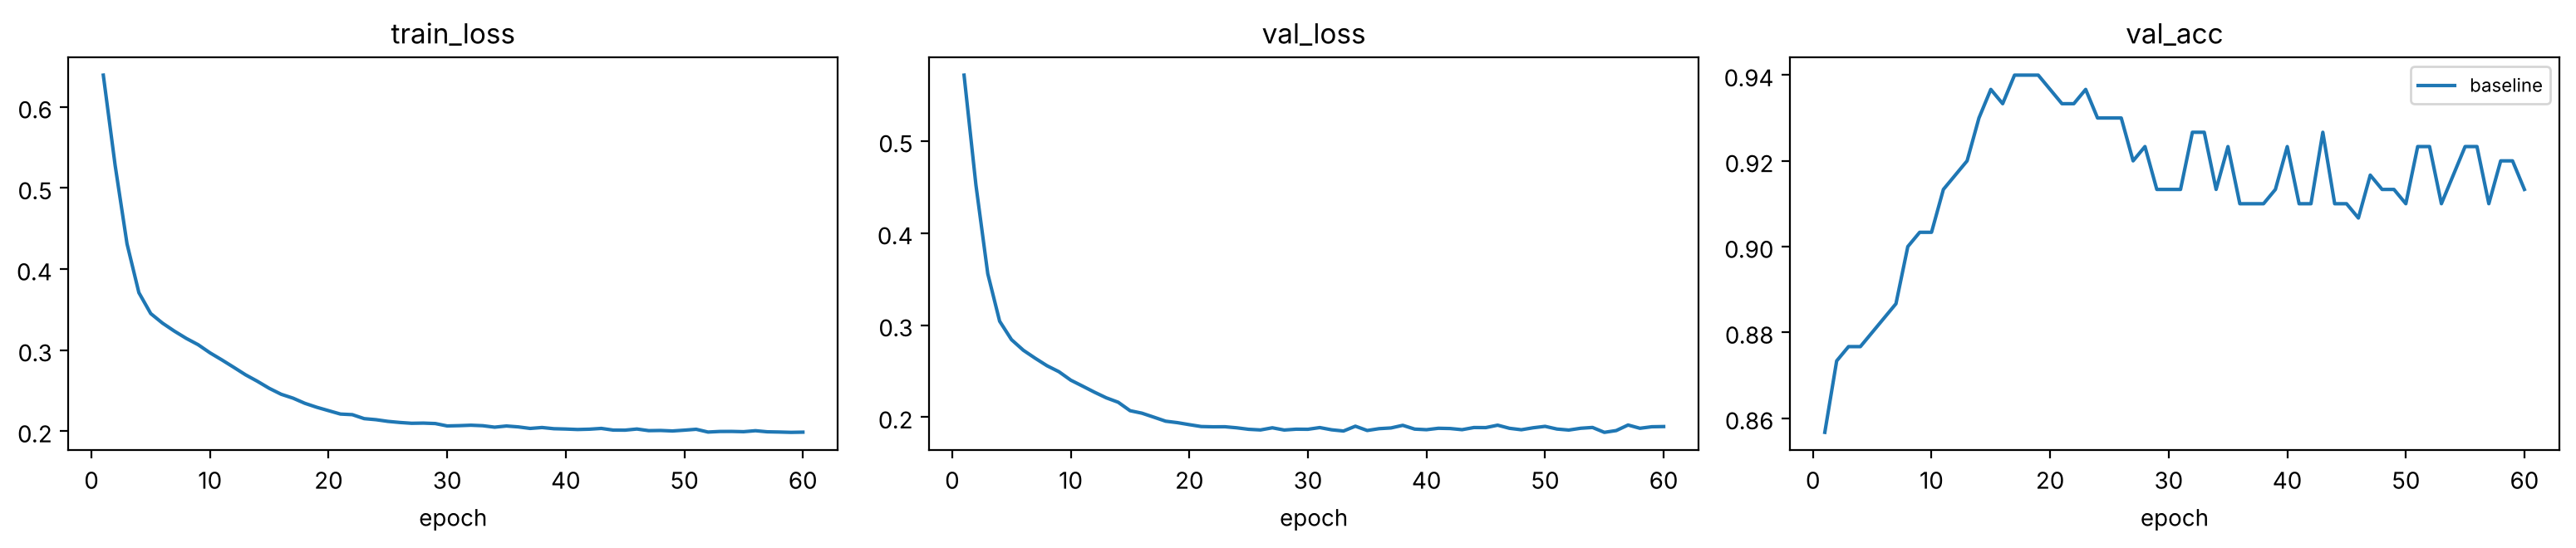

In [6]:
set_seed()
model = make_mlp(hidden=32, depth=2)
print("parameters:", n_params(model))
hist = fit(model, train_dl, val_dl, epochs=60, opt="adam", lr=1e-3, verbose=10)
plot_runs({"baseline": hist}, metrics=("train_loss", "val_loss", "val_acc"))

In [7]:
# Metrics beyond accuracy, computed on the validation set
model.eval()
with torch.no_grad():
    Xv, yv = val_dl.dataset.tensors
    probs = torch.softmax(model(Xv.to(device)), dim=1)[:, 1].cpu().numpy()
pred = (probs >= 0.5).astype(int)
yv = yv.numpy()
print(f"accuracy  {accuracy_score(yv, pred):.3f}")
print(f"precision {precision_score(yv, pred):.3f}   (of predicted 1s, how many are really 1)")
print(f"recall    {recall_score(yv, pred):.3f}   (of real 1s, how many we found)")
print(f"F1        {f1_score(yv, pred):.3f}")
print("confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(yv, pred))

accuracy  0.913
precision 0.925   (of predicted 1s, how many are really 1)
recall    0.900   (of real 1s, how many we found)
F1        0.912
confusion matrix [[TN FP] [FN TP]]:
 [[139  11]
 [ 15 135]]


In [8]:
# Loss and accuracy can disagree: same accuracy, very different loss
y_true = torch.tensor([0, 0, 1, 1])
confident = torch.tensor([[4., -4.], [4., -4.], [-4., 4.], [4., -4.]])   # last one: confidently WRONG
hesitant  = torch.tensor([[.2, -.2], [.2, -.2], [-.2, .2], [.2, -.2]])   # last one: slightly wrong
ce = nn.CrossEntropyLoss()
for name, logits in [("confident", confident), ("hesitant", hesitant)]:
    acc = (logits.argmax(1) == y_true).float().mean().item()
    print(f"{name:9s} accuracy {acc:.2f} | loss {ce(logits, y_true).item():.3f}")

confident accuracy 0.75 | loss 2.000
hesitant  accuracy 0.75 | loss 0.613


🔍 **What to notice**
* Both curves fall quickly and end close together (here validation is even slightly *below* training — that happens when the
  validation split happens to contain fewer very noisy points). A small gap either way is healthy.
* Precision and recall are both reported, because accuracy alone hides *which kind* of mistakes the model makes.
* Same 75% accuracy, but the confident model's single mistake costs far more loss. **Validation loss can rise while accuracy stays flat**
  when the model becomes over-confident — an early sign of overfitting.

✍️ **Exercise 1:** Change the decision threshold from 0.5 to 0.3 and 0.7. How do precision and recall move?

---
## 2. Underfitting and overfitting

| | Train loss | Val loss | Gap | Fix |
|---|---|---|---|---|
| **Underfitting** | high | high | small | bigger model, more epochs, better features, higher LR |
| **Good fit** | low | low | small | keep it |
| **Overfitting** | very low | rising | **large** | more data, regularization, smaller model, early stopping |

We create all three on purpose. For overfitting we give a **big** network only **60** training points.

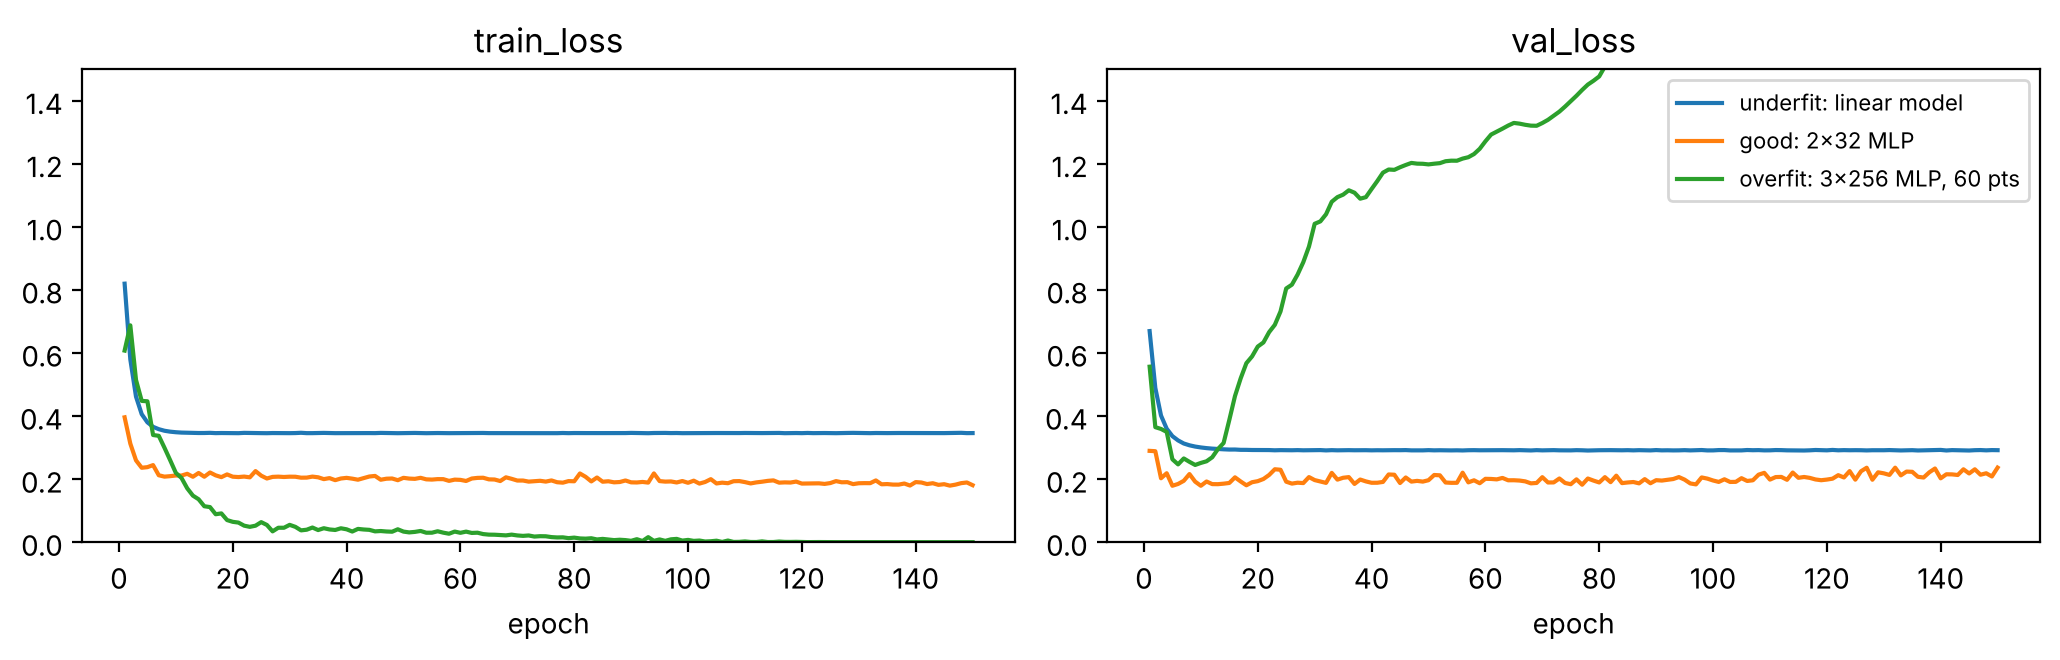

,final_train_loss,final_val_loss,best_val_loss,best_epoch,final_val_acc,gap
underfit: linear model,0.346,0.292,0.291,78.0,0.883,-0.054
good: 2×32 MLP,0.181,0.237,0.179,10.0,0.917,0.056
"overfit: 3×256 MLP, 60 pts",0.000,1.872,0.245,9.0,0.873,1.872


In [9]:
runs = {}
set_seed()
runs["underfit: linear model"] = fit(nn.Linear(2, 2), train_dl, val_dl, epochs=150, lr=1e-2)
set_seed()
runs["good: 2×32 MLP"] = fit(make_mlp(hidden=32, depth=2), train_dl, val_dl, epochs=150, lr=1e-2)

small_train_dl, small_val_dl = moons_loaders(n_train=60)
set_seed()
runs["overfit: 3×256 MLP, 60 pts"] = fit(make_mlp(hidden=256, depth=3), small_train_dl, small_val_dl, epochs=150, lr=1e-2)

plot_runs(runs, ylim=(0, 1.5))
summary(runs)

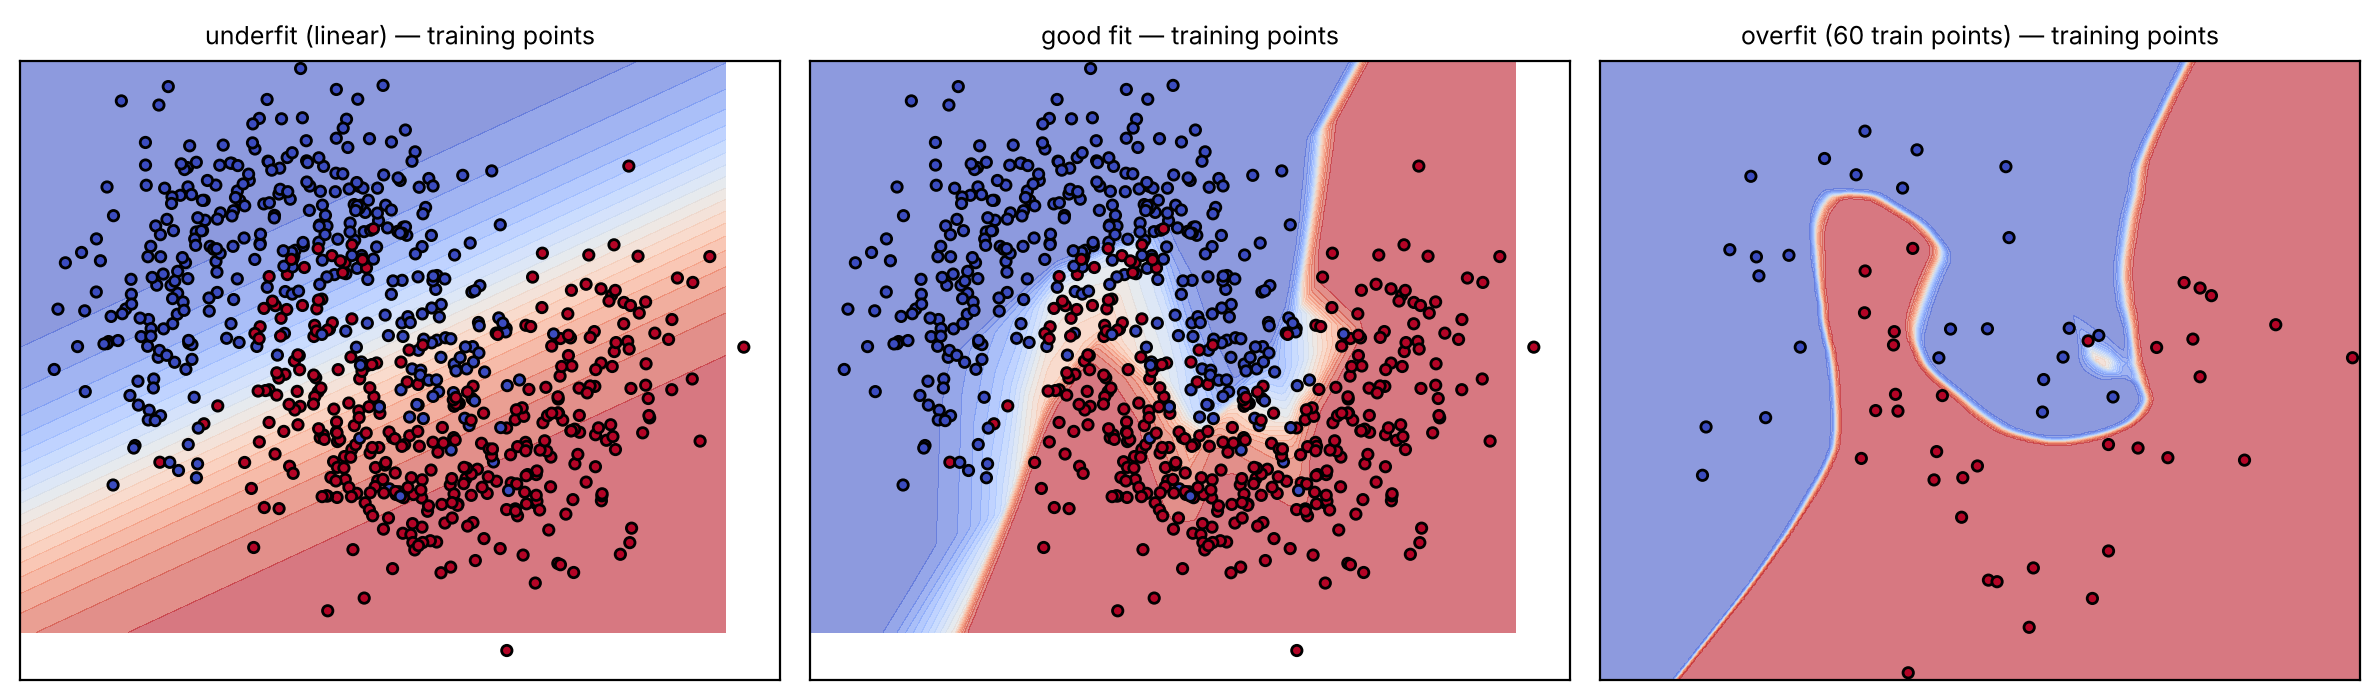

In [10]:
def plot_boundary(model, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        zz = torch.softmax(model(grid.to(device)), 1)[:, 1].cpu().numpy().reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.6)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=14)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, m, dl, ep) in zip(axes, [
        ("underfit (linear)", nn.Linear(2, 2), train_dl, 150),
        ("good fit", make_mlp(hidden=32, depth=2), train_dl, 150),
        ("overfit (60 train points)", make_mlp(hidden=256, depth=3), small_train_dl, 150)]):
    set_seed(); fit(m, dl, val_dl, epochs=ep, lr=1e-2)
    Xt, yt = dl.dataset.tensors
    plot_boundary(m, Xt.numpy(), yt.numpy(), ax, name + " — training points")
plt.tight_layout(); plt.show()

🔍 **What to notice**
* **Linear:** both losses plateau around 0.3 — clearly worse than the MLP. A straight line can't follow the curved moons (underfitting).
* **Good fit:** both low and close together.
* **Overfit:** training loss heads to ~0 while validation loss **turns upward**; the boundary contorts to wrap around individual
  training points. The best validation loss happened early — later epochs only memorised.

✍️ **Exercise 2:** Give the 3×256 model the full training set. Does it still overfit? What does that tell you about data vs model size?

---
## 3. Learning rate and optimizer choices

The **learning rate** (LR) scales every update: `w ← w − lr × gradient`. It is usually the most important hyperparameter.

* Too **small** → slow progress, may stop before converging.
* Too **large** → loss oscillates or explodes (`nan`).
* A good LR is usually found on a **log scale**: 1e-4, 1e-3, 1e-2, 1e-1…

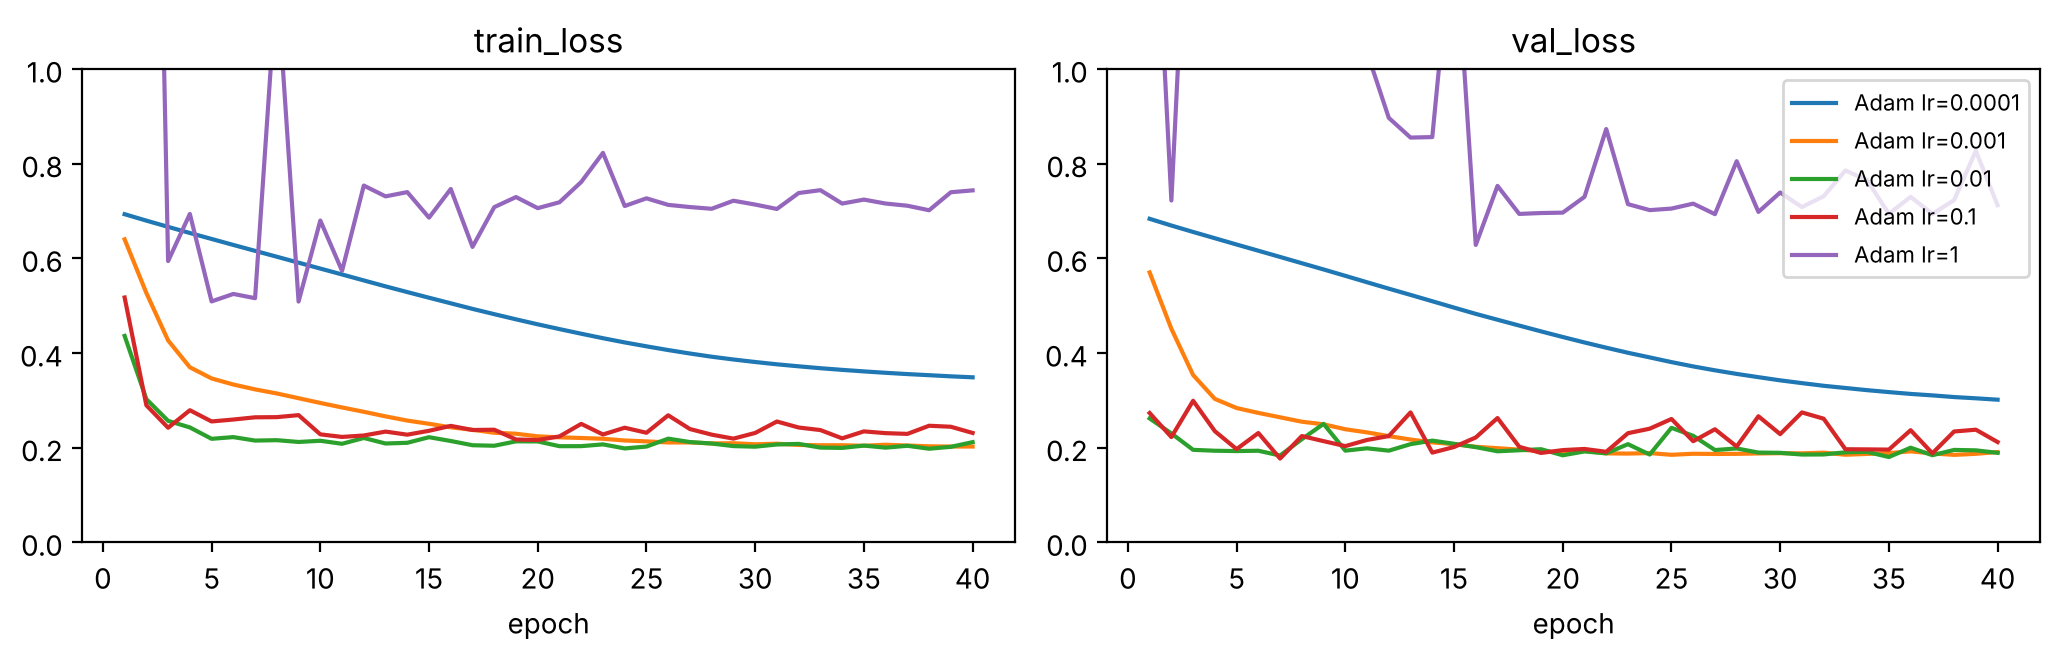

,final_train_loss,best_val_loss,best_epoch,final_val_acc
Adam lr=0.0001,0.348,0.301,40.0,0.880
Adam lr=0.001,0.202,0.185,38.0,0.907
Adam lr=0.01,0.211,0.180,35.0,0.927
Adam lr=0.1,0.231,0.177,7.0,0.917
Adam lr=1,0.743,0.628,16.0,0.500


In [11]:
runs = {}
for lr in [1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
    set_seed()
    runs[f"Adam lr={lr:g}"] = fit(make_mlp(hidden=32, depth=2), train_dl, val_dl, epochs=40, opt="adam", lr=lr)
plot_runs(runs, metrics=("train_loss", "val_loss"), ylim=(0, 1.0))
summary(runs)[["final_train_loss", "best_val_loss", "best_epoch", "final_val_acc"]]

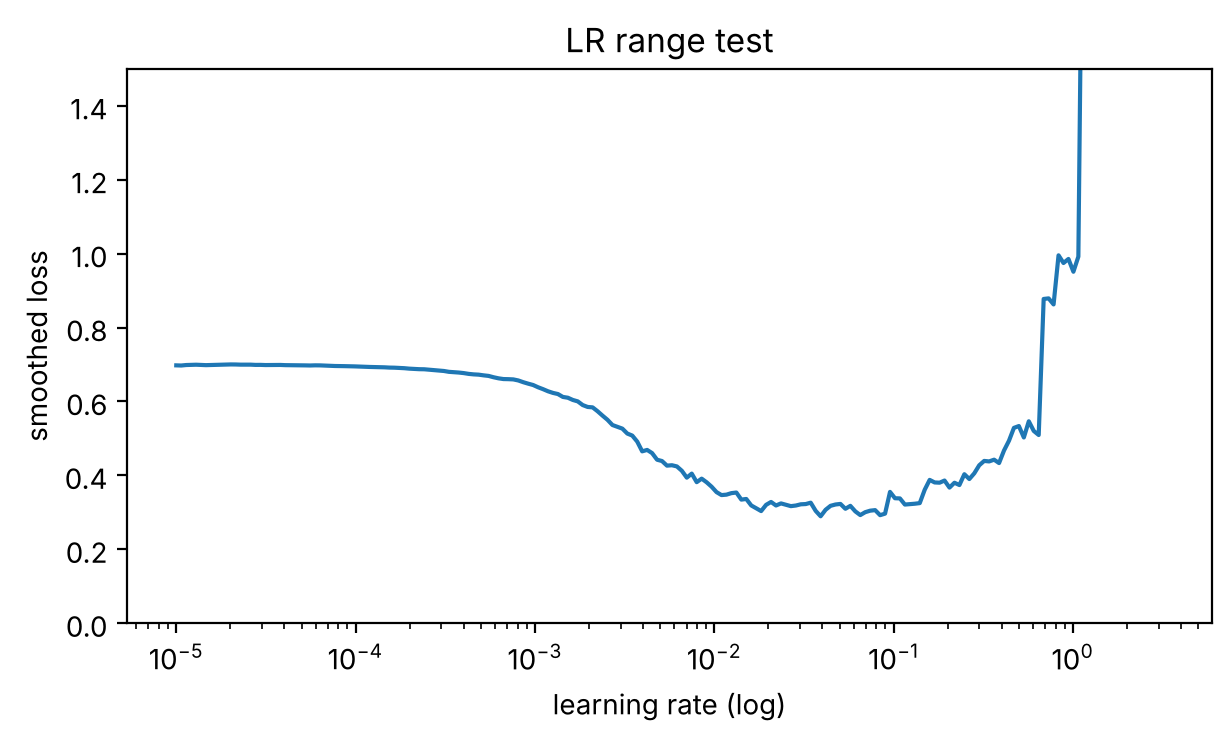

LR with the lowest smoothed loss: 0.0392 → a safe choice is ~10× smaller


In [12]:
# A quick "LR range test": increase LR every batch and watch the loss
set_seed()
m = make_mlp(hidden=32, depth=2).to(device)
opt = torch.optim.Adam(m.parameters(), lr=1e-5)
lrs, losses = np.logspace(-5, 0.5, 200), []
it = iter(train_dl)
for lr in lrs:
    try: xb, yb = next(it)
    except StopIteration:
        it = iter(train_dl); xb, yb = next(it)
    for g in opt.param_groups: g["lr"] = lr
    loss = nn.functional.cross_entropy(m(xb), yb)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
smooth = pd.Series(losses).ewm(alpha=0.1).mean()
plt.semilogx(lrs, smooth); plt.ylim(0, 1.5)
plt.xlabel("learning rate (log)"); plt.ylabel("smoothed loss"); plt.title("LR range test"); plt.show()
print("LR with the lowest smoothed loss:", f"{lrs[smooth.idxmin()]:.3g}", "→ a safe choice is ~10× smaller")

🔍 **What to notice**
* `1e-4` is far too slow in 40 epochs; `1.0` is unstable. The middle values reach low validation loss.
* The **range test** gives a starting LR in one quick pass: pick roughly 10× below the point where loss is lowest, before it blows up.

✍️ **Exercise 3:** Repeat the sweep with `opt="sgd"`. Is SGD's best learning rate the same as Adam's?

---
## 4. SGD and Adam / AdamW

| Optimizer | Update idea | Typical LR | Notes |
|---|---|---|---|
| **SGD** | `w −= lr·g` | 0.01–0.1 | simple; noisy; sensitive to LR |
| **SGD + momentum** | keep a running velocity `v = μv + g`; `w −= lr·v` | 0.01–0.1, μ=0.9 | rolls through flat areas and noise; strong final results in vision |
| **Adam** | per-weight step from running mean (m) and variance (v) of gradients: `w −= lr·m̂/(√v̂+ε)` | 1e-3 | fast, little tuning; great default |
| **AdamW** | Adam + *decoupled* weight decay `w −= lr·λ·w` | 1e-3, λ≈0.01 | the modern default for most deep learning (transformers, etc.) |

**Why AdamW?** In `Adam(weight_decay=λ)` the decay is added to the gradient and then rescaled by Adam's per-weight step, so
weights with large gradient history get *less* regularization. AdamW applies the decay directly to the weights — the behaviour you expect.

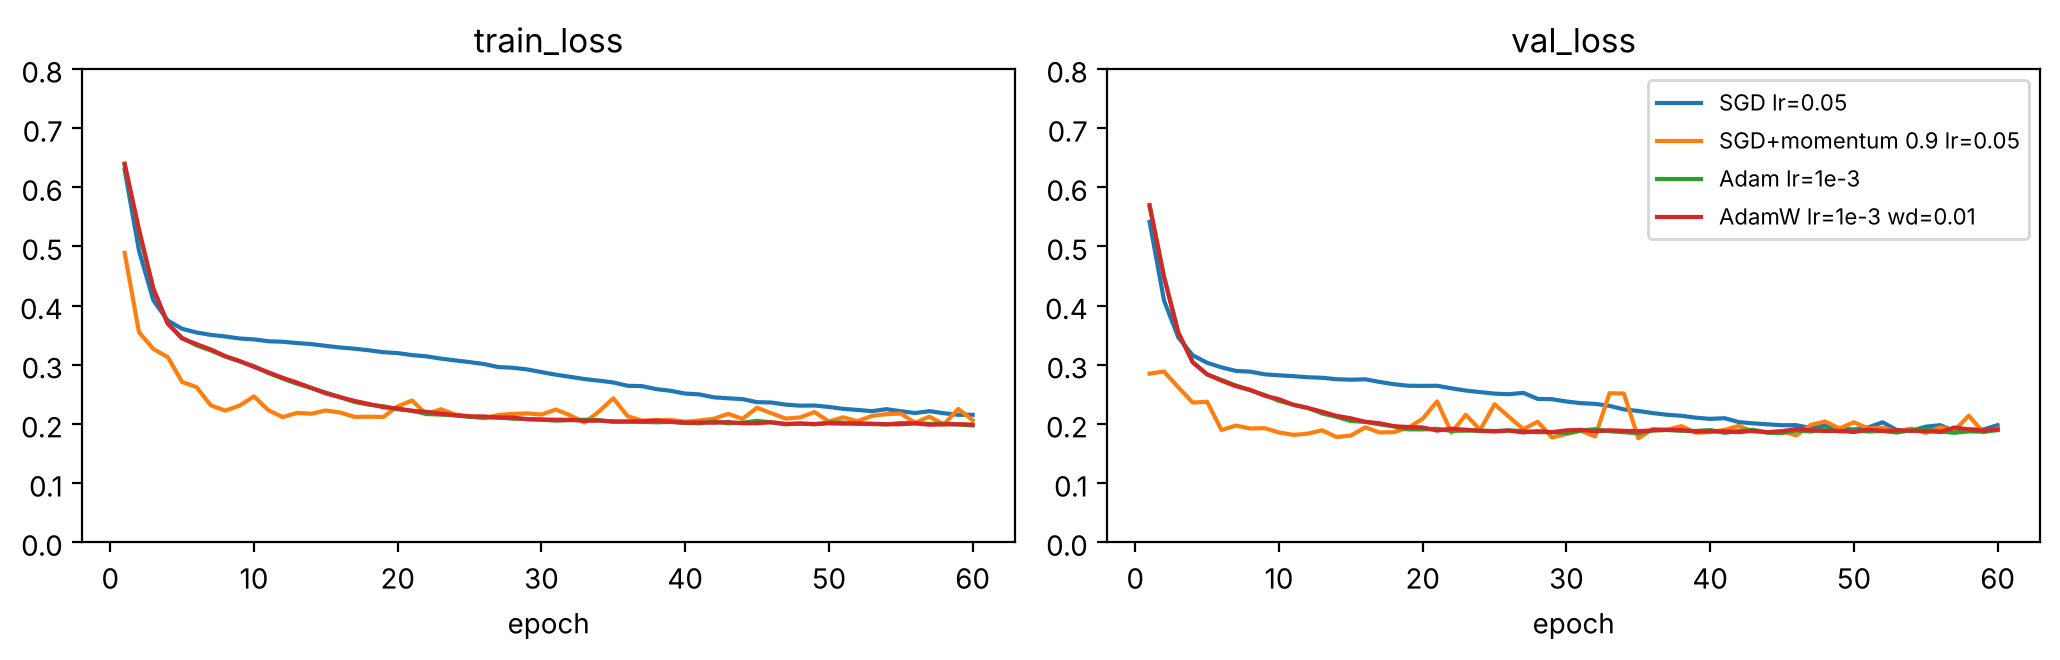

,final_train_loss,best_val_loss,best_epoch,final_val_acc
SGD lr=0.05,0.215,0.188,57.0,0.913
SGD+momentum 0.9 lr=0.05,0.206,0.176,35.0,0.930
Adam lr=1e-3,0.197,0.184,35.0,0.910
AdamW lr=1e-3 wd=0.01,0.199,0.186,27.0,0.913


In [13]:
runs = {}
for name, kw in [("SGD lr=0.05",                dict(opt="sgd", lr=0.05)),
                 ("SGD+momentum 0.9 lr=0.05",   dict(opt="sgd", lr=0.05, momentum=0.9)),
                 ("Adam lr=1e-3",               dict(opt="adam", lr=1e-3)),
                 ("AdamW lr=1e-3 wd=0.01",      dict(opt="adamw", lr=1e-3, wd=0.01))]:
    set_seed()
    runs[name] = fit(make_mlp(hidden=32, depth=2), train_dl, val_dl, epochs=60, **kw)
plot_runs(runs, metrics=("train_loss", "val_loss"), ylim=(0, 0.8))
summary(runs)[["final_train_loss", "best_val_loss", "best_epoch", "final_val_acc"]]

In [14]:
# Peek inside Adam: its state stores the running averages per parameter
m = make_mlp(hidden=4, depth=1)
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
xb, yb = next(iter(train_dl))
nn.functional.cross_entropy(m(xb), yb).backward(); opt.step()
first_weight = m[0].weight
state = opt.state[first_weight]
print("Adam keeps for each parameter:", list(state.keys()))
print("exp_avg (m) shape:", tuple(state["exp_avg"].shape), "| exp_avg_sq (v) shape:", tuple(state["exp_avg_sq"].shape))

Adam keeps for each parameter: ['step', 'exp_avg', 'exp_avg_sq']
exp_avg (m) shape: (4, 2) | exp_avg_sq (v) shape: (4, 2)


🔍 **What to notice**
* Plain SGD at this LR is the slowest (its best epoch is near the end); **momentum** gets there noticeably sooner and lower.
* Adam and AdamW reach a low loss with the default LR and no tuning — that's why they're the usual starting point.
* Adam stores two extra numbers per weight (`exp_avg`, `exp_avg_sq`): it uses ~3× the memory of plain SGD for optimizer state.

✍️ **Exercise 4:** Try `SGD+momentum` with `lr=0.2` and `lr=0.01`. Which optimizer is most sensitive to the learning rate?

---
## 5. Regularization: weight decay and dropout

Regularization makes the model **prefer simpler solutions**, trading a bit of training loss for better validation loss.

* **Weight decay (L2):** every step shrinks weights a little toward 0 → smoother functions. In PyTorch: `AdamW(..., weight_decay=λ)`.
* **Dropout(p):** during training, randomly zero a fraction *p* of activations (and scale the rest by 1/(1−p)). The network can't rely on
  any single neuron → a built-in ensemble. **Off at evaluation** (`model.eval()`).

We use the **overfitting setup** from Section 2 (3×256 network, 60 training points), where regularization has something to fix.

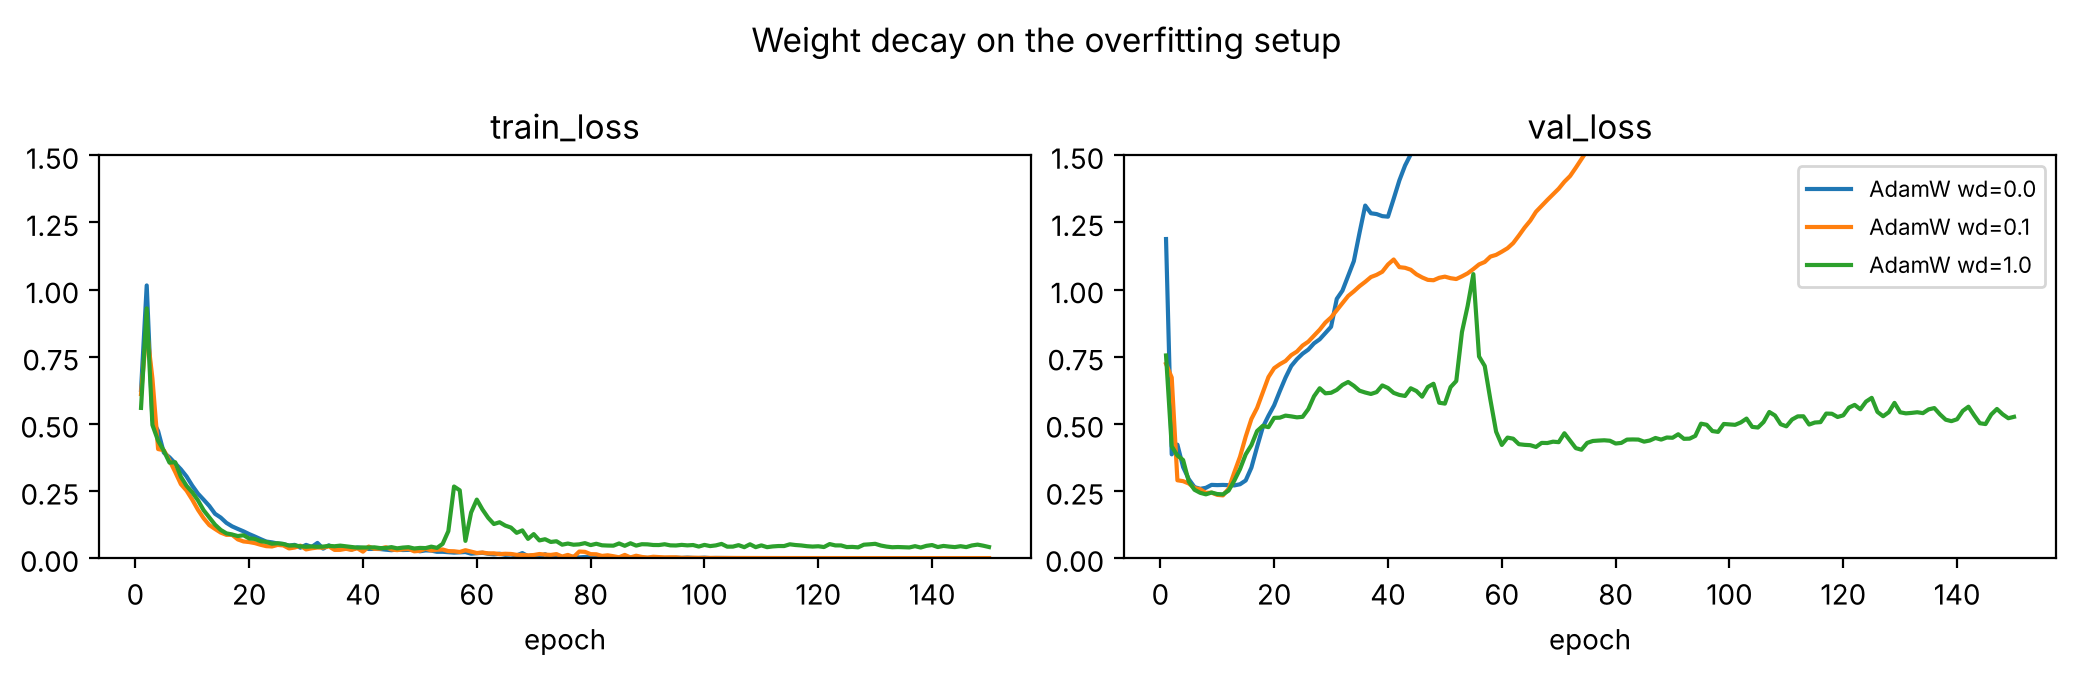

,final_train_loss,final_val_loss,best_val_loss,best_epoch,final_val_acc,gap
AdamW wd=0.0,0.000,2.322,0.258,7.0,0.887,2.322
AdamW wd=0.1,0.001,1.696,0.234,11.0,0.897,1.696
AdamW wd=1.0,0.042,0.526,0.238,11.0,0.873,0.485


In [15]:
runs = {}
for wd in [0.0, 0.1, 1.0]:
    set_seed()
    runs[f"AdamW wd={wd}"] = fit(make_mlp(hidden=256, depth=3), small_train_dl, small_val_dl,
                                 epochs=150, opt="adamw", lr=1e-2, wd=wd)
plot_runs(runs, ylim=(0, 1.5), title="Weight decay on the overfitting setup")
summary(runs)

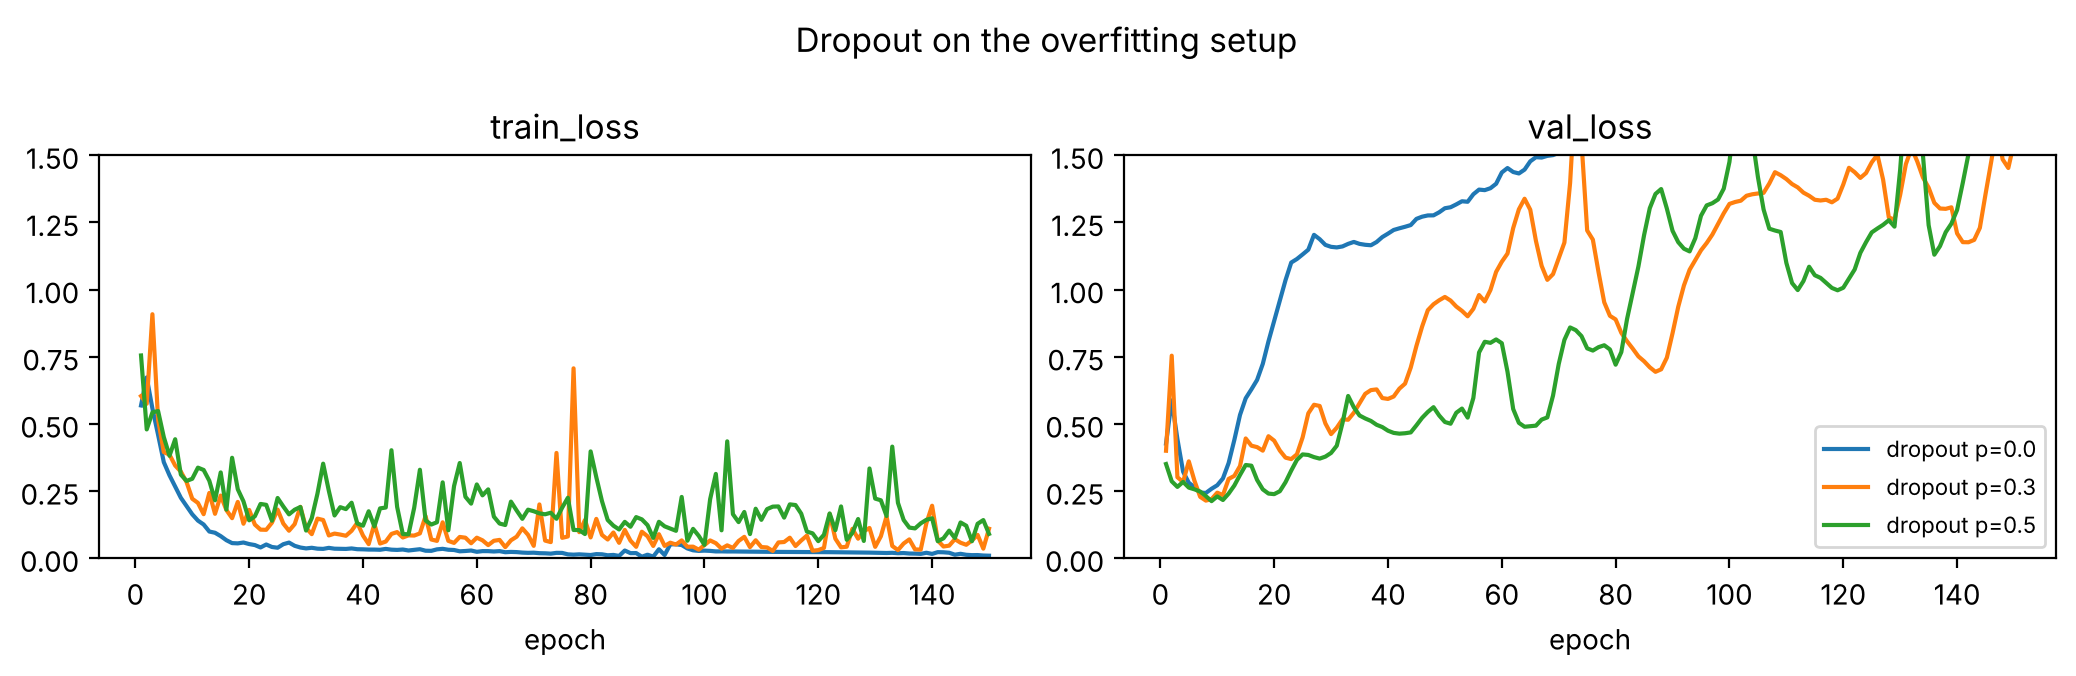

,final_train_loss,final_val_loss,best_val_loss,best_epoch,final_val_acc,gap
dropout p=0.0,0.009,1.736,0.243,8.0,0.883,1.727
dropout p=0.3,0.110,1.547,0.215,8.0,0.880,1.437
dropout p=0.5,0.091,1.975,0.213,9.0,0.870,1.885


In [16]:
runs = {}
for p in [0.0, 0.3, 0.5]:
    set_seed()
    runs[f"dropout p={p}"] = fit(make_mlp(hidden=256, depth=3, dropout=p), small_train_dl, small_val_dl,
                                 epochs=150, opt="adam", lr=1e-2)
plot_runs(runs, ylim=(0, 1.5), title="Dropout on the overfitting setup")
summary(runs)

In [17]:
# Dropout is random in train mode and switched off in eval mode
set_seed()
drop_net = make_mlp(hidden=8, depth=1, dropout=0.5)
x1 = torch.tensor([[0.5, -0.2]])
drop_net.train()
print("train mode, 3 calls:", [np.round(drop_net(x1).detach().numpy()[0].astype(float), 3).tolist() for _ in range(3)])
drop_net.eval()
print("eval mode,  3 calls:", [np.round(drop_net(x1).detach().numpy()[0].astype(float), 3).tolist() for _ in range(3)])

train mode, 3 calls: [[-0.295, -0.233], [-0.289, 0.295], [-0.427, 0.408]]
eval mode,  3 calls: [[-0.364, 0.083], [-0.364, 0.083], [-0.364, 0.083]]


🔍 **What to notice**
* Without regularization the validation loss climbs far above training loss. **Strong weight decay (λ = 1.0) shrinks the gap
  dramatically** and keeps the final validation loss low — at the price of a higher training loss. That trade is the whole point.
* **Dropout helps only a little here:** both p = 0.3 and p = 0.5 lower the best validation loss (0.24 → 0.21), but only p = 0.3 narrows the final gap a little; p = 0.5 doesn't.
  With just 60 points and 150 epochs, a 3×256 network can still memorise. In practice dropout is combined with **early stopping**
  (next section) and weight decay rather than used alone.
* λ and *p* are hyperparameters to tune on the validation set; too much regularization underfits.
* In train mode dropout gives a different output each call; in eval mode it's deterministic. **Forgetting `model.eval()`** makes
  validation scores noisy and too pessimistic.

✍️ **Exercise 5:** Combine `dropout=0.3` with `wd=0.1`. Is the combination better than either alone?

---
## 6. Early stopping and checkpointing

**Early stopping:** watch validation loss; if it hasn't improved for `patience` epochs, stop and **restore the best weights**.

**Checkpointing:** save the model whenever validation improves. A checkpoint should hold everything needed to resume:
model weights, optimizer state (Adam's averages!), epoch, and the metric.

In [18]:
ckpt_dir = Path("checkpoints"); ckpt_dir.mkdir(exist_ok=True)
ckpt_path = ckpt_dir / "best_overfit_model.pt"

set_seed()
es = EarlyStopping(patience=15, min_delta=1e-3)
model_es = make_mlp(hidden=256, depth=3)
h_es = fit(model_es, small_train_dl, small_val_dl, epochs=300, opt="adam", lr=1e-2,
           early_stopping=es, ckpt_path=ckpt_path, verbose=10)
print(f"\nStopped after {len(h_es)} of 300 epochs | best epoch {es.best_epoch} | best val loss {es.best:.3f}")

epoch   1 | train 0.595 / 0.567 | val 0.279 / 0.877 | lr 0.01000
epoch  10 | train 0.202 / 0.900 | val 0.256 / 0.917 | lr 0.01000
epoch  20 | train 0.058 / 0.983 | val 0.799 / 0.870 | lr 0.01000
Early stop at epoch 23; best epoch 8

Stopped after 23 of 300 epochs | best epoch 8 | best val loss 0.249


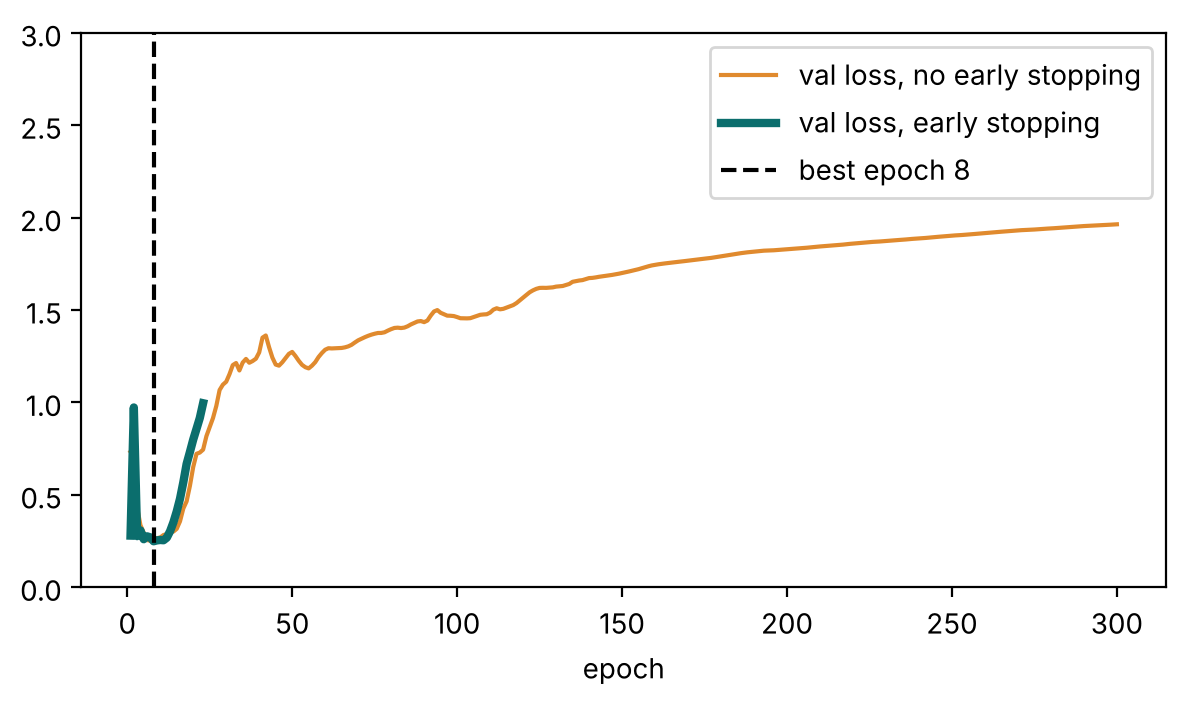

final val loss without early stopping: 1.964
val loss of restored best model     : 0.249


In [19]:
set_seed()
h_full = fit(make_mlp(hidden=256, depth=3), small_train_dl, small_val_dl, epochs=300, opt="adam", lr=1e-2)
fig, ax = plt.subplots()
ax.plot(h_full.index, h_full.val_loss, label="val loss, no early stopping", color="#E08A2E")
ax.plot(h_es.index, h_es.val_loss, label="val loss, early stopping", color="#0B6E6D", lw=3)
ax.axvline(es.best_epoch, ls="--", color="k", label=f"best epoch {es.best_epoch}")
ax.set_ylim(0, 3); ax.set_xlabel("epoch"); ax.legend(); plt.show()
print("final val loss without early stopping:", round(h_full.val_loss.iloc[-1], 3))
print("val loss of restored best model     :", round(run_epoch(model_es, small_val_dl, nn.CrossEntropyLoss())[0], 3))

In [20]:
# Load the checkpoint from disk into a fresh model — e.g. after a crash, or to deploy
ckpt = torch.load(ckpt_path, map_location=device)
print("checkpoint keys:", list(ckpt.keys()), "| saved at epoch", ckpt["epoch"])

restored = make_mlp(hidden=256, depth=3).to(device)
restored.load_state_dict(ckpt["model_state"])
opt_resume = torch.optim.Adam(restored.parameters(), lr=1e-2)
opt_resume.load_state_dict(ckpt["optimizer_state"])        # resume with Adam's memory intact
print("restored val loss:", round(run_epoch(restored, small_val_dl, nn.CrossEntropyLoss())[0], 3),
      "| matches checkpoint:", round(ckpt["val_loss"], 3))
print(f"file size: {ckpt_path.stat().st_size/1024:.1f} KB")

checkpoint keys: ['epoch', 'model_state', 'optimizer_state', 'val_loss'] | saved at epoch 8
restored val loss: 0.249 | matches checkpoint: 0.249
file size: 1567.1 KB


🔍 **What to notice**
* Early stopping ended the run long before 300 epochs and kept the weights from the best epoch.
* Without it, validation loss keeps climbing — the final model is much worse than the best one it passed through.
* The checkpoint reloads into a fresh model with an identical validation loss. Save `state_dict()` (weights), not the whole model object.

✍️ **Exercise 6:** Try `patience=3` and `patience=50`. What are the risks of each?

---
## 7. Batch normalization

**BatchNorm** normalises each feature over the current mini-batch, then lets the network rescale it:

$$\hat{x} = \frac{x - \mu_{batch}}{\sqrt{\sigma^2_{batch} + \epsilon}}, \qquad y = \gamma\,\hat{x} + \beta \quad(\gamma, \beta \text{ are learned})$$

* **Training mode:** uses the batch's own mean/variance, and updates *running* averages.
* **Eval mode:** uses the stored running averages, so one example gives the same answer whatever batch it's in.
* Effects: smoother optimisation, tolerates higher learning rates, trains deep networks faster; mild regularization.
* Caveats: tiny batches give noisy statistics; behaviour differs between train and eval.

In [21]:
x = torch.tensor([[1.0, 10.0], [2.0, 20.0], [3.0, 30.0], [4.0, 40.0]])   # batch of 4, 2 features
bn = nn.BatchNorm1d(2)
bn.train()
out = bn(x)
manual = (x - x.mean(0)) / torch.sqrt(x.var(0, unbiased=False) + bn.eps)
print("BatchNorm output:\n", out.detach().round(decimals=4))
print("matches manual formula:", torch.allclose(out, manual, atol=1e-5))
print("running_mean after one batch:", bn.running_mean, " (momentum 0.1 → 0.1 × batch mean)")
bn.eval()
print("eval-mode output for the same batch (uses running stats):\n", bn(x).detach().round(decimals=3))

BatchNorm output:
 tensor([[-1.3416, -1.3416],
        [-0.4472, -0.4472],
        [ 0.4472,  0.4472],
        [ 1.3416,  1.3416]])
matches manual formula: True
running_mean after one batch: tensor([0.2500, 2.5000])  (momentum 0.1 → 0.1 × batch mean)
eval-mode output for the same batch (uses running stats):
 tensor([[0.7260, 1.7890],
        [1.6940, 4.1750],
        [2.6630, 6.5610],
        [3.6310, 8.9470]])


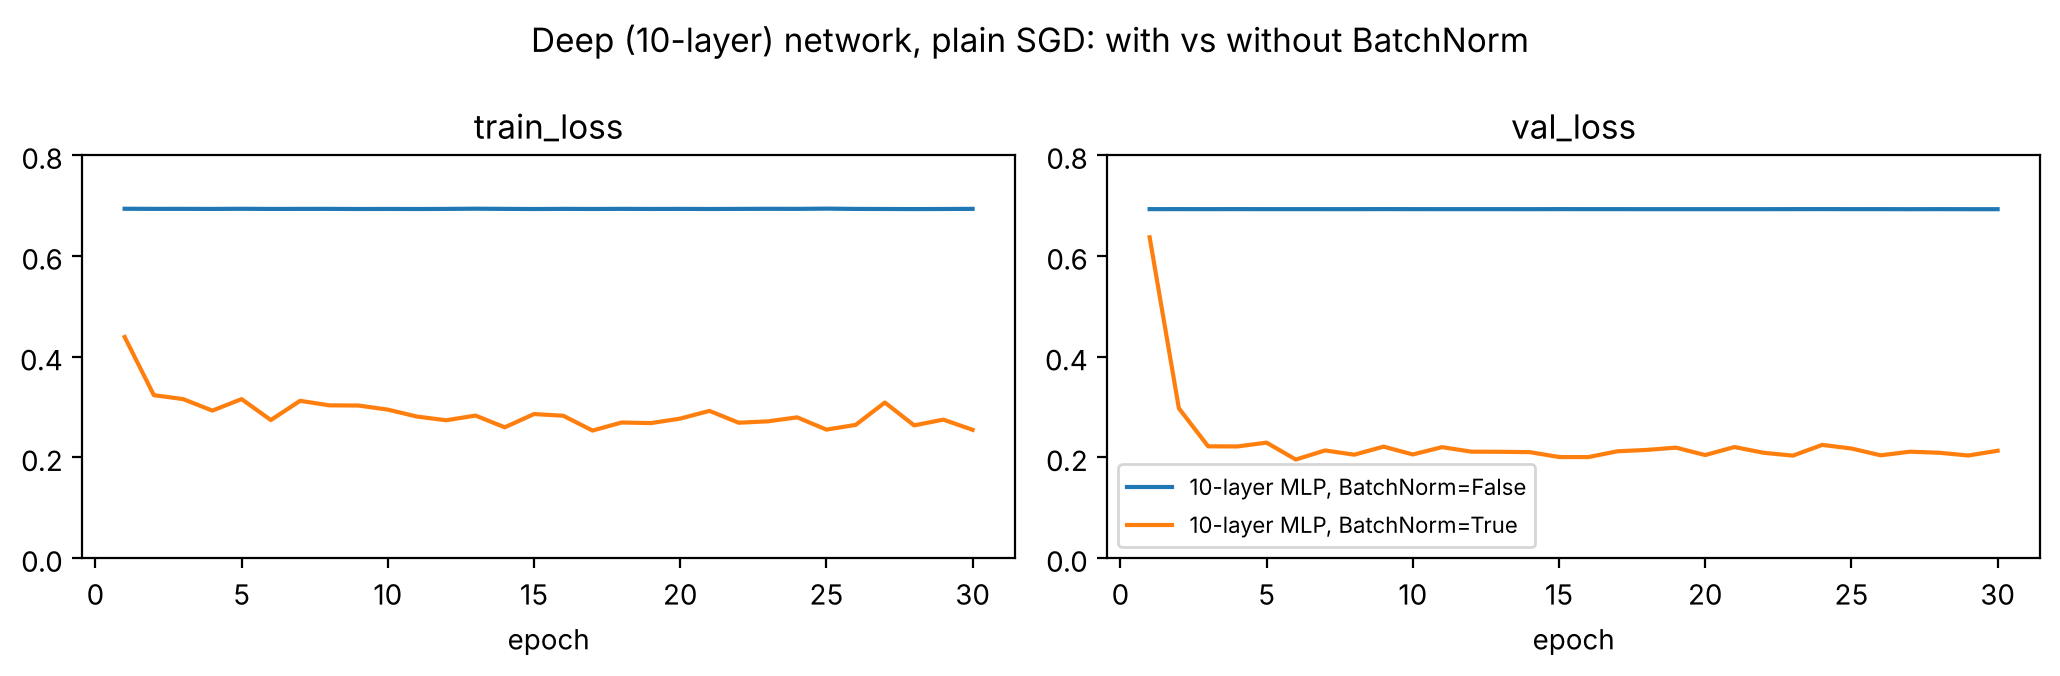

,final_train_loss,best_val_loss,best_epoch,final_val_acc
"10-layer MLP, BatchNorm=False",0.694,0.693,30.0,0.500
"10-layer MLP, BatchNorm=True",0.255,0.196,6.0,0.923


In [22]:
runs = {}
for bnorm in [False, True]:
    set_seed()
    runs[f"10-layer MLP, BatchNorm={bnorm}"] = fit(make_mlp(hidden=64, depth=10, batchnorm=bnorm),
                                                   train_dl, val_dl, epochs=30, opt="sgd", lr=0.05)
plot_runs(runs, ylim=(0, 0.8), title="Deep (10-layer) network, plain SGD: with vs without BatchNorm")
summary(runs)[["final_train_loss", "best_val_loss", "best_epoch", "final_val_acc"]]

🔍 **What to notice**
* BatchNorm's output matches the formula exactly: each column now has mean 0 and variance 1.
* After one batch, the running mean is only 10% of the way to the batch mean — that's why eval-mode output differs early in training.
* With plain SGD, the 10-layer network **without** BatchNorm doesn't learn at all: loss stays at 0.693 (= ln 2, a coin flip) and
  accuracy at 50%, because signals and gradients fade through so many layers. **With** BatchNorm the same network trains normally.

✍️ **Exercise 7:** Train the BatchNorm model with `batch_size=2` (pass it to `moons_loaders`). What happens to the curves, and why?

---
## 8. Class imbalance and data augmentation

### 8.1 Class imbalance
When one class is rare (fraud, disease), **accuracy lies**: predicting “never” can score 95%. Use metrics that look at the rare class
(recall, precision, F1, balanced accuracy, PR-AUC) and consider:

* **Class weights** in the loss: mistakes on the rare class cost more → `nn.CrossEntropyLoss(weight=...)`
* **Oversampling** the rare class in each batch → `WeightedRandomSampler`
* Choosing the **decision threshold** on validation data

In [23]:
Xi, yi = make_classification(n_samples=4000, n_features=10, n_informative=4, n_redundant=2,
                             weights=[0.95, 0.05], class_sep=0.8, flip_y=0.01, random_state=SEED)
Xi_tr, Xi_va, yi_tr, yi_va = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=SEED)
sc = StandardScaler().fit(Xi_tr); Xi_tr, Xi_va = sc.transform(Xi_tr), sc.transform(Xi_va)
print("class counts (train):", np.bincount(yi_tr), "→ minority share", round(yi_tr.mean(), 3))
print("accuracy of always predicting 0:", round(accuracy_score(yi_va, np.zeros_like(yi_va)), 3))

class counts (train): [2650  150] → minority share 0.054
accuracy of always predicting 0: 0.947


In [24]:
def evaluate_imbalance(model, X, y):
    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(X, dtype=torch.float32).to(device)).argmax(1).cpu().numpy()
    return dict(accuracy=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),
                minority_recall=recall_score(y, pred), minority_precision=precision_score(y, pred, zero_division=0),
                minority_f1=f1_score(y, pred))

results = {}
# (a) plain
tr_dl, va_dl = to_loaders(Xi_tr, yi_tr, Xi_va, yi_va)
set_seed(); m_plain = make_mlp(n_in=10, hidden=32, depth=2)
fit(m_plain, tr_dl, va_dl, epochs=30, lr=1e-3)
results["plain"] = evaluate_imbalance(m_plain, Xi_va, yi_va)

# (b) class-weighted loss: weight = inverse frequency
counts = np.bincount(yi_tr)
w = torch.tensor(len(yi_tr) / (2 * counts), dtype=torch.float32)
print("class weights:", w.numpy().round(2))
set_seed(); m_w = make_mlp(n_in=10, hidden=32, depth=2)
fit(m_w, tr_dl, va_dl, epochs=30, lr=1e-3, loss_fn=nn.CrossEntropyLoss(weight=w.to(device)))
results["class weights"] = evaluate_imbalance(m_w, Xi_va, yi_va)

# (c) oversampling with WeightedRandomSampler
sample_w = (1.0 / counts)[yi_tr]
sampler = WeightedRandomSampler(torch.tensor(sample_w, dtype=torch.double), num_samples=len(yi_tr),
                                replacement=True, generator=torch.Generator().manual_seed(SEED))
tr_dl_s, _ = to_loaders(Xi_tr, yi_tr, Xi_va, yi_va, sampler=sampler)
xb, yb = next(iter(tr_dl_s)); print("minority share in one oversampled batch:", round(yb.float().mean().item(), 2))
set_seed(); m_s = make_mlp(n_in=10, hidden=32, depth=2)
fit(m_s, tr_dl_s, va_dl, epochs=30, lr=1e-3)
results["oversampling"] = evaluate_imbalance(m_s, Xi_va, yi_va)

pd.DataFrame(results).T.round(3)

class weights: [0.53 9.33]


minority share in one oversampled batch: 0.53


,accuracy,balanced_acc,minority_recall,minority_precision,minority_f1
plain,0.980,0.820,0.641,0.976,0.774
class weights,0.934,0.899,0.859,0.440,0.582
oversampling,0.961,0.920,0.875,0.589,0.704


🔍 **What to notice**
* Always predicting the majority class already scores ~95% accuracy — accuracy is useless here.
* The plain model misses many minority cases (low recall). Class weights and oversampling raise **minority recall** a lot,
  usually at the cost of precision (more false alarms). Which trade-off is right is a business decision.

### 8.2 Data augmentation
Augmentation creates new, realistic training examples by transforming existing ones (shift, flip, rotate, crop, noise for images;
synonyms or back-translation for text). It teaches **invariances** and fights overfitting when data is scarce.

Rules: augment **training data only**, keep labels valid (a flipped “6” is not a “6”!), and do it on the fly inside the Dataset.

Below: handwritten digits (8×8 pixels) with only **150 training images**.

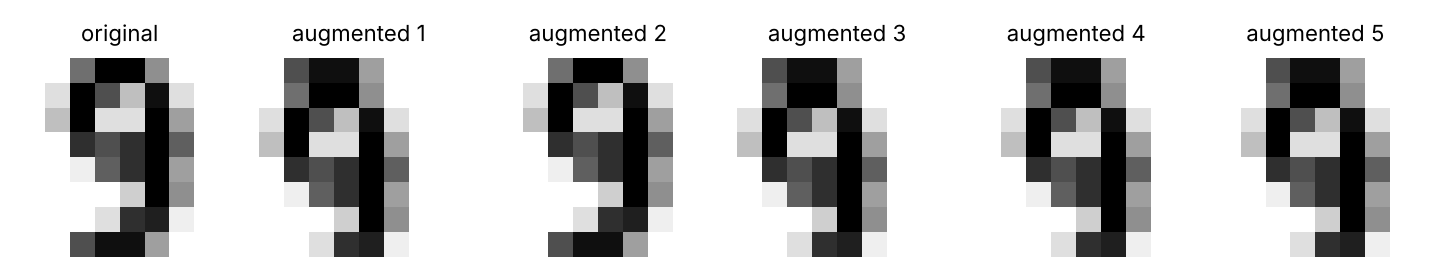

In [25]:
digits = load_digits()
Xd = (digits.images / 16.0).astype(np.float32)          # (1797, 8, 8), values 0..1
yd = digits.target
Xd_tr, Xd_va, yd_tr, yd_va = train_test_split(Xd, yd, train_size=150, test_size=600, stratify=yd, random_state=SEED)

class DigitsDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = torch.tensor(X), torch.tensor(y, dtype=torch.long), augment
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        img = self.X[i]
        if self.augment:
            dx, dy = torch.randint(-1, 2, (2,)).tolist()            # shift up to 1 pixel
            img = torch.roll(img, shifts=(dy, dx), dims=(0, 1))
        return img.unsqueeze(0), self.y[i]                         # (1, 8, 8)

set_seed()
aug_ds = DigitsDataset(Xd_tr, yd_tr, augment=True)
fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
axes[0].imshow(Xd_tr[0], cmap="gray_r"); axes[0].set_title("original", fontsize=8)
for k, ax in enumerate(axes[1:], 1):
    ax.imshow(aug_ds[0][0][0], cmap="gray_r"); ax.set_title(f"augmented {k}", fontsize=8)
for ax in axes: ax.axis("off")
plt.show()

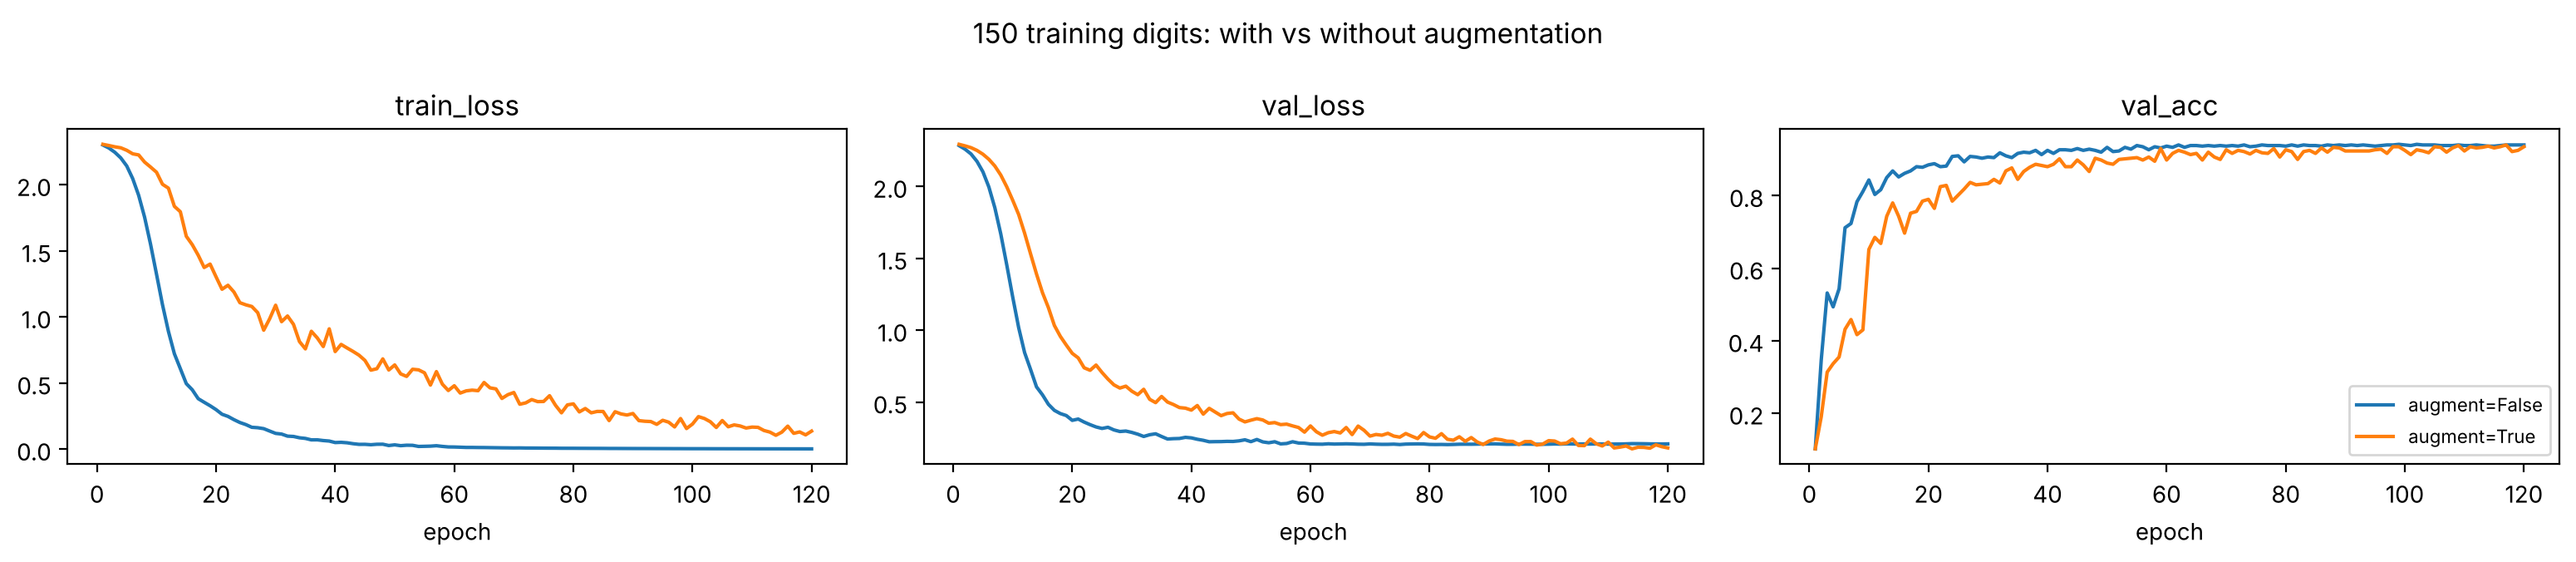

,final_train_loss,final_val_loss,best_val_loss,gap,final_val_acc
augment=False,0.002,0.209,0.204,0.207,0.940
augment=True,0.137,0.181,0.174,0.044,0.935


In [26]:
def small_cnn():
    return nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                         nn.MaxPool2d(2), nn.Flatten(), nn.Linear(32 * 4 * 4, 64), nn.ReLU(), nn.Linear(64, 10))

runs = {}
for aug in [False, True]:
    set_seed()
    g = torch.Generator().manual_seed(SEED)
    tr = DataLoader(DigitsDataset(Xd_tr, yd_tr, augment=aug), batch_size=32, shuffle=True, generator=g)
    va = DataLoader(DigitsDataset(Xd_va, yd_va, augment=False), batch_size=256)   # never augment validation
    runs[f"augment={aug}"] = fit(small_cnn(), tr, va, epochs=120, lr=1e-3)
plot_runs(runs, metrics=("train_loss", "val_loss", "val_acc"), title="150 training digits: with vs without augmentation")
summary(runs)[["final_train_loss", "final_val_loss", "best_val_loss", "gap", "final_val_acc"]]

🔍 **What to notice**
* Without augmentation the CNN memorises the 150 images: training loss goes to almost 0 and the train–val **gap is large**.
* With augmentation the training loss stays much higher — every epoch sees slightly shifted images — the gap shrinks and the
  **validation loss improves**. Accuracy ends up about the same (~94%): on tiny, centred 8×8 digits there's little room to gain.
  On real photos, augmentation (crops, flips, colour changes) usually gives much bigger accuracy gains.
* Augmented training is a harder task, so it **needs more epochs** — with only 60 epochs it would still be catching up.

✍️ **Exercise 8:** Add a random horizontal flip to the digits augmentation. Does it help or hurt? Why might flipping be a bad idea for digits?

---
## 9. Learning-rate scheduling

A schedule changes the LR during training: **big steps early** to make progress, **small steps late** to settle into a minimum.

| Scheduler | Shape | Step when |
|---|---|---|
| `StepLR` | drop by γ every N epochs | each epoch |
| `CosineAnnealingLR` | smooth cosine decay to ~0 | each epoch |
| `OneCycleLR` | warm up, then anneal | **each batch** |
| `ReduceLROnPlateau` | cut LR when val loss stalls | each epoch, given `val_loss` |

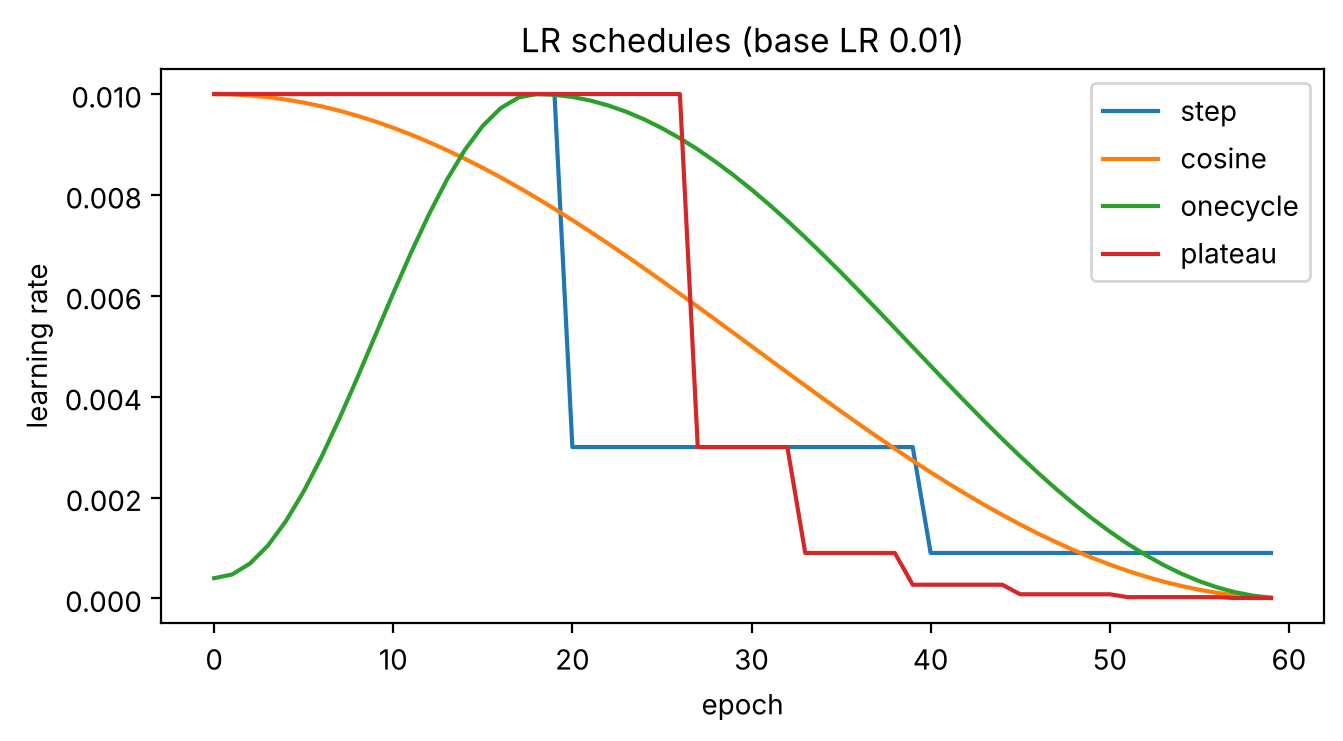

In [27]:
def lr_trace(name, epochs=60, steps_per_epoch=25, base_lr=0.01):
    p = torch.nn.Parameter(torch.zeros(1))
    opt = torch.optim.SGD([p], lr=base_lr)
    sched, mode = make_scheduler(name, opt, epochs, steps_per_epoch)
    lrs = []
    for e in range(epochs):
        lrs.append(opt.param_groups[0]["lr"])
        if mode == "batch":
            for _ in range(steps_per_epoch): opt.step(); sched.step()
        elif mode == "epoch":
            opt.step(); sched.step()
        elif mode == "plateau":
            opt.step(); sched.step(1.0 if e > 20 else 1.0 - e * 0.01)   # fake loss that stalls after epoch 20
    return lrs

plt.figure(figsize=(7.5, 3.6))
for name in ["step", "cosine", "onecycle", "plateau"]:
    plt.plot(lr_trace(name), label=name)
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.legend(); plt.title("LR schedules (base LR 0.01)"); plt.show()

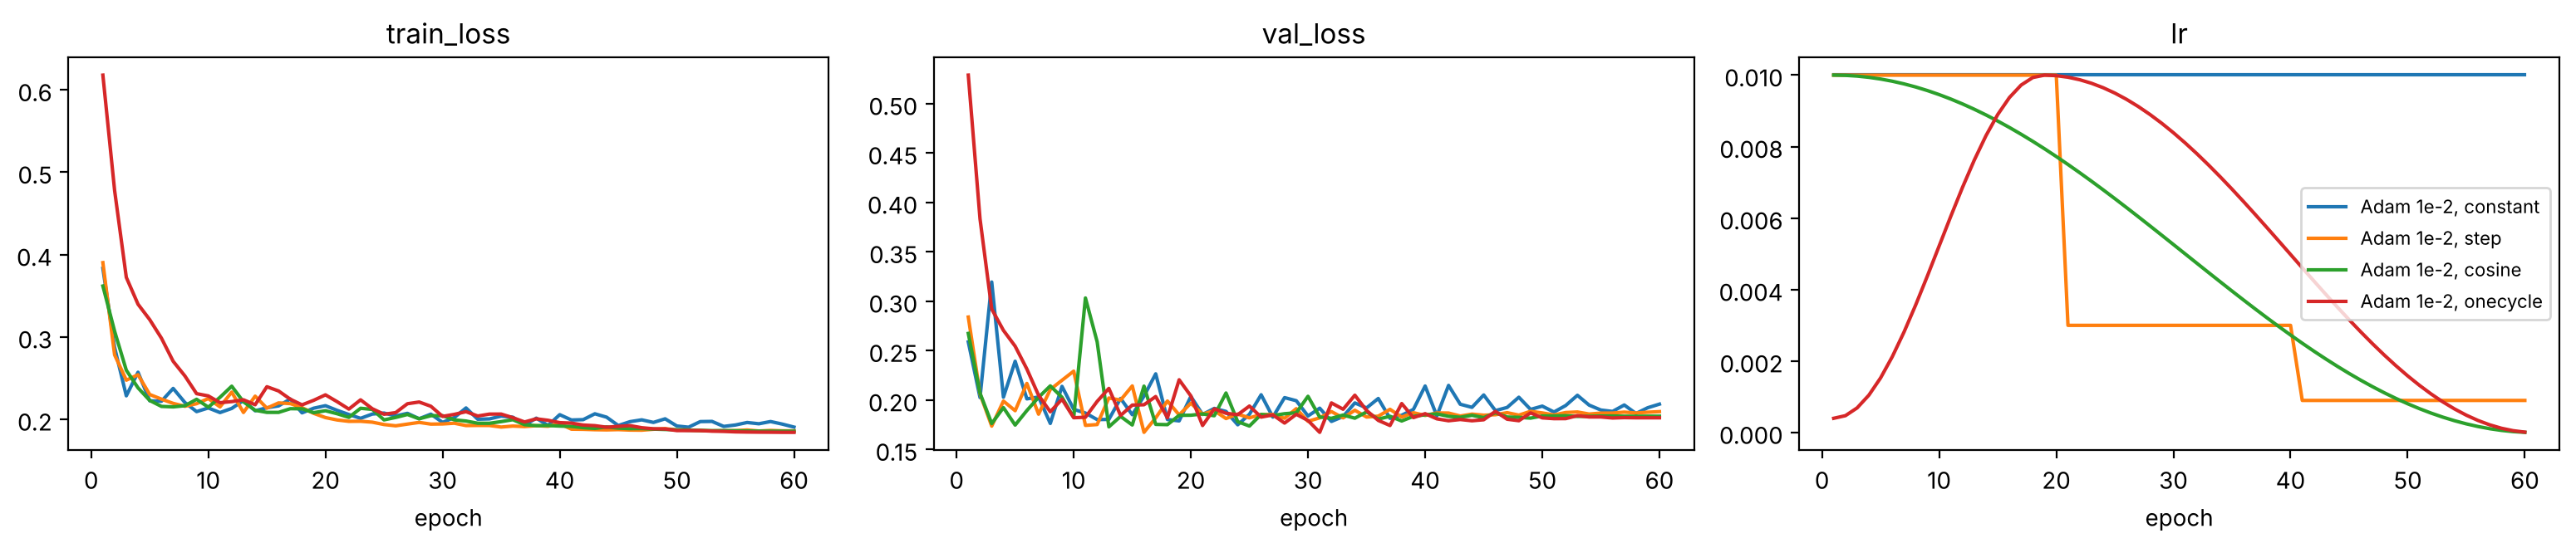

,final_train_loss,final_val_loss,best_val_loss,final_val_acc
"Adam 1e-2, constant",0.191,0.196,0.175,0.907
"Adam 1e-2, step",0.186,0.188,0.167,0.913
"Adam 1e-2, cosine",0.186,0.184,0.173,0.923
"Adam 1e-2, onecycle",0.184,0.182,0.167,0.927


In [28]:
runs = {}
for sched in [None, "step", "cosine", "onecycle"]:
    set_seed()
    runs[f"Adam 1e-2, {sched or 'constant'}"] = fit(make_mlp(hidden=64, depth=2), train_dl, val_dl,
                                                   epochs=60, opt="adam", lr=1e-2, sched=sched)
plot_runs(runs, metrics=("train_loss", "val_loss", "lr"), ylim=None)
summary(runs)[["final_train_loss", "final_val_loss", "best_val_loss", "final_val_acc"]]

🔍 **What to notice**
* Decaying schedules let the loss **settle** in the last epochs: cosine and one-cycle end with slightly lower final validation loss
  than the constant LR. On this easy problem the differences are small; on large models and long runs they matter much more.
* Look at the `lr` panel: one schedule, four very different shapes.
* OneCycle steps every batch and starts with a warm-up, which also protects the first updates from huge gradients.

✍️ **Exercise 9:** Use `sched="plateau"` with `fit()`. Plot the `lr` column: when did the learning rate drop?

---
## 10. Experiment tracking and reproducibility

You will run dozens of experiments. Without records you can't answer “which settings gave that result?”.
For every run, store: **config** (all hyperparameters), **metrics per epoch**, **final summary**, **environment** (versions, device),
and a **run id**. Tools like **MLflow, Weights & Biases or TensorBoard** do this for teams; below is a dependency-free tracker.

**Reproducibility checklist:** seed Python/NumPy/PyTorch; seeded `Generator` for `DataLoader` shuffling and splits;
same data version; log library versions; on GPU, `torch.use_deterministic_algorithms(True)` for bit-exact runs (slower).

In [29]:
@dataclass
class Config:
    name: str
    hidden: int = 64
    depth: int = 2
    dropout: float = 0.0
    opt: str = "adamw"
    lr: float = 1e-3
    wd: float = 0.01
    epochs: int = 60
    sched: str | None = None
    batch_size: int = 32
    seed: int = SEED

class Tracker:
    def __init__(self, root="runs"):
        self.root = Path(root); self.root.mkdir(exist_ok=True)
    def run(self, cfg: Config):
        run_id = f"{cfg.name}-{time.strftime('%Y%m%d-%H%M%S')}"
        d = self.root / run_id; d.mkdir()
        set_seed(cfg.seed)
        tr, va = moons_loaders(batch_size=cfg.batch_size, seed=cfg.seed)
        model = make_mlp(hidden=cfg.hidden, depth=cfg.depth, dropout=cfg.dropout)
        h = fit(model, tr, va, epochs=cfg.epochs, opt=cfg.opt, lr=cfg.lr, wd=cfg.wd, sched=cfg.sched, seed=cfg.seed)
        h.to_csv(d / "metrics.csv")
        summary_ = dict(run_id=run_id, best_val_loss=round(h.val_loss.min(), 4),
                        best_epoch=int(h.val_loss.idxmin()), final_val_acc=round(h.val_acc.iloc[-1], 4))
        env = dict(python=platform.python_version(), torch=torch.__version__, device=device)
        (d / "config.json").write_text(json.dumps(asdict(cfg), indent=2))
        (d / "summary.json").write_text(json.dumps({**summary_, **env}, indent=2))
        torch.save(model.state_dict(), d / "model.pt")
        return {**asdict(cfg), **summary_}, model

tracker = Tracker()
records = []
for cfg in [Config("baseline"),
            Config("dropout", dropout=0.3),
            Config("cosine", sched="cosine", lr=1e-2),
            Config("sgd-momentum", opt="sgd", lr=0.05, wd=0.0)]:
    rec, _ = tracker.run(cfg)
    records.append(rec)
runs_table = pd.DataFrame(records)[["name", "opt", "lr", "wd", "dropout", "sched", "best_val_loss", "best_epoch", "final_val_acc"]]
runs_table.sort_values("best_val_loss")

,name,opt,lr,wd,dropout,sched,best_val_loss,best_epoch,final_val_acc
2,cosine,adamw,0.010,0.01,0.0,cosine,0.1733,26,0.9233
3,sgd-momentum,sgd,0.050,0.00,0.0,NaN,0.1741,54,0.9367
0,baseline,adamw,0.001,0.01,0.0,NaN,0.1759,35,0.9067
1,dropout,adamw,0.001,0.01,0.3,NaN,0.1850,50,0.9200


In [30]:
# What one run folder contains
one = sorted(Path("runs").iterdir())[0]
print(one.name, "→", sorted(p.name for p in one.iterdir()))
print((one / "summary.json").read_text())

baseline-20261125-210708 → ['config.json', 'metrics.csv', 'model.pt', 'summary.json']
{
  "run_id": "baseline-20261125-210708",
  "best_val_loss": 0.1759,
  "best_epoch": 35,
  "final_val_acc": 0.9067,
  "python": "3.13.18",
  "torch": "2.15.0+cu132",
  "device": "cpu"
}


In [31]:
# Reproducibility test: the same config twice must give identical results
rec_a, model_a = tracker.run(Config("repro-a"))
rec_b, model_b = tracker.run(Config("repro-b"))
same_weights = all(torch.equal(p, q) for p, q in zip(model_a.state_dict().values(), model_b.state_dict().values()))
print("best val loss:", rec_a["best_val_loss"], rec_b["best_val_loss"], "| identical weights:", same_weights)

# ...and a different seed gives a (slightly) different result
rec_c, _ = tracker.run(Config("repro-seed7", seed=7))
print("seed 7 best val loss:", rec_c["best_val_loss"])

best val loss: 0.1759 0.1759 | identical weights: True


seed 7 best val loss: 0.1945


🔍 **What to notice**
* Each run leaves a folder with `config.json`, `metrics.csv`, `summary.json` and `model.pt`, so any number in the table can be
  traced back and the model reloaded.
* Same config + same seed → **bit-identical weights**. A different seed changes the result a little — report results over a few seeds
  rather than picking the luckiest one.

✍️ **Exercise 10:** Add `git_commit` and a hash of the training data to the summary. Then run each config with seeds 1, 2, 3 and report mean ± std.

---
## Summary

| Topic | Remember |
|---|---|
| Train vs val | Train loss shows learning; **val loss shows generalisation**; pick metrics that match the goal |
| Under/overfitting | Underfit: both high. Overfit: train ↓, val ↑ with a widening gap |
| Learning rate | Search on a log scale; range test for a starting point |
| Optimizers | Adam/AdamW = strong default (1e-3); SGD+momentum can match with tuning |
| Regularization | Weight decay (AdamW) and dropout trade training fit for validation performance |
| Early stopping | Patience on val loss; restore best; checkpoint weights + optimizer + epoch |
| BatchNorm | Normalise per batch; faster, more stable deep training; mind train vs eval mode |
| Imbalance | Accuracy misleads; use recall/F1; class weights or oversampling |
| Augmentation | Training data only; label-preserving transforms; strong fix for small data |
| Schedulers | Big steps early, small late: step, cosine, one-cycle, plateau |
| Tracking | Config + metrics + env + seed for every run; same seed ⇒ same result |